In [1]:
import numpy as np
%pip install lime
import lime
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")
dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [8]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.086 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0665 | train acc: 0.4335 | val loss: 0.9903 | val acc: 0.6076
Epoch 02 | train loss: 0.9229 | train acc: 0.7184 | val loss: 0.9213 | val acc: 0.6076


/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 03 | train loss: 0.8120 | train acc: 0.7848 | val loss: 0.8772 | val acc: 0.6203
Epoch 04 | train loss: 0.7254 | train acc: 0.7373 | val loss: 0.8524 | val acc: 0.5570
Epoch 05 | train loss: 0.6536 | train acc: 0.7943 | val loss: 0.8349 | val acc: 0.6329
Epoch 06 | train loss: 0.5787 | train acc: 0.8766 | val loss: 0.8211 | val acc: 0.6076
Epoch 07 | train loss: 0.5087 | train acc: 0.9367 | val loss: 0.8117 | val acc: 0.6076
Epoch 08 | train loss: 0.4479 | train acc: 0.9494 | val loss: 0.8043 | val acc: 0.6076
Epoch 09 | train loss: 0.3813 | train acc: 0.9620 | val loss: 0.7985 | val acc: 0.6329
Epoch 10 | train loss: 0.3209 | train acc: 0.9620 | val loss: 0.7963 | val acc: 0.6203
Epoch 11 | train loss: 0.2755 | train acc: 0.9589 | val loss: 0.7986 | val acc: 0.6203
Epoch 12 | train loss: 0.2320 | train acc: 0.9652 | val loss: 0.8031 | val acc: 0.6203
Epoch 13 | train loss: 0.1927 | train acc: 0.9747 | val loss: 0.8107 | val acc: 0.6203
Epoch 14 | train loss: 0.1622 | train acc: 

... (4 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0292 | train acc: 0.4462 | val loss: 0.9656 | val acc: 0.4304
Epoch 02 | train loss: 0.8984 | train acc: 0.7247 | val loss: 0.8867 | val acc: 0.6582
Epoch 03 | train loss: 0.8053 | train acc: 0.8386 | val loss: 0.8302 | val acc: 0.6582
Epoch 04 | train loss: 0.7202 | train acc: 0.8418 | val loss: 0.7946 | val acc: 0.6329
Epoch 05 | train loss: 0.6529 | train acc: 0.8608 | val loss: 0.7716 | val acc: 0.6709
Epoch 06 | train loss: 0.5816 | train acc: 0.9019 | val loss: 0.7552 | val acc: 0.6582
Epoch 07 | train loss: 0.5119 | train acc: 0.9399 | val loss: 0.7404 | val acc: 0.6962
Epoch 08 | train loss: 0.4483 | train acc: 0.9462 | val loss: 0.7291 | val acc: 0.6709
Epoch 09 | train loss: 0.3831 | train acc: 0.9462 | val loss: 0.7164 | val acc: 0.6962
Epoch 10 | train loss: 0.3253 | train acc: 0.9589 | val loss: 0.7109 | val acc: 0.6835
Epoch 11 | train loss: 0.2740 | train acc: 0.9652 | val loss: 0.7078 | val acc: 0.6962
Epoch 12 | train loss: 0.2337 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0507 | train acc: 0.5000 | val loss: 0.9902 | val acc: 0.5316
Epoch 02 | train loss: 0.9077 | train acc: 0.6994 | val loss: 0.8945 | val acc: 0.5443
Epoch 03 | train loss: 0.8030 | train acc: 0.7247 | val loss: 0.8220 | val acc: 0.5316
Epoch 04 | train loss: 0.7152 | train acc: 0.7405 | val loss: 0.7706 | val acc: 0.5696
Epoch 05 | train loss: 0.6394 | train acc: 0.8133 | val loss: 0.7355 | val acc: 0.5696
Epoch 06 | train loss: 0.5706 | train acc: 0.8671 | val loss: 0.7076 | val acc: 0.5696
Epoch 07 | train loss: 0.5003 | train acc: 0.9272 | val loss: 0.6832 | val acc: 0.5823
Epoch 08 | train loss: 0.4343 | train acc: 0.9367 | val loss: 0.6700 | val acc: 0.6203
Epoch 09 | train loss: 0.3713 | train acc: 0.9399 | val loss: 0.6654 | val acc: 0.6076
Epoch 10 | train loss: 0.3142 | train acc: 0.9462 | val loss: 0.6664 | val acc: 0.6076
Epoch 11 | train loss: 0.2612 | train acc: 0.9557 | val loss: 0.6626 | val acc: 0.6203
Epoch 12 | train loss: 0.2211 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.087 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0670 | train acc: 0.4747 | val loss: 1.0167 | val acc: 0.5063
Epoch 02 | train loss: 0.9506 | train acc: 0.5443 | val loss: 0.9344 | val acc: 0.5063
Epoch 03 | train loss: 0.8381 | train acc: 0.5443 | val loss: 0.8827 | val acc: 0.5063
Epoch 04 | train loss: 0.7489 | train acc: 0.5475 | val loss: 0.8759 | val acc: 0.5063
Epoch 05 | train loss: 0.6731 | train acc: 0.6487 | val loss: 0.8785 | val acc: 0.5190
Epoch 06 | train loss: 0.5924 | train acc: 0.8513 | val loss: 0.8651 | val acc: 0.5949
Epoch 07 | train loss: 0.4804 | train acc: 0.8987 | val loss: 0.8467 | val acc: 0.6076
Epoch 08 | train loss: 0.3633 | train acc: 0.9399 | val loss: 0.8354 | val acc: 0.5949
Epoch 09 | train loss: 0.2550 | train acc: 0.9525 | val loss: 0.8465 | val acc: 0.6203
Epoch 10 | train loss: 0.1712 | train acc: 0.9589 | val loss: 0.8772 | val acc: 0.6456
Epoch 11 | train loss: 0.1151 | train acc: 0.9652 | val loss: 0.9332 | val acc: 0.6203
Epoch 12 | train loss: 0.0808 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0453 | train acc: 0.5285 | val loss: 0.9911 | val acc: 0.5443
Epoch 02 | train loss: 0.9290 | train acc: 0.6994 | val loss: 0.9016 | val acc: 0.5823
Epoch 03 | train loss: 0.8101 | train acc: 0.6076 | val loss: 0.8445 | val acc: 0.5570
Epoch 04 | train loss: 0.7341 | train acc: 0.5791 | val loss: 0.8356 | val acc: 0.5696
Epoch 05 | train loss: 0.6533 | train acc: 0.7500 | val loss: 0.8110 | val acc: 0.6076
Epoch 06 | train loss: 0.5502 | train acc: 0.9209 | val loss: 0.7894 | val acc: 0.6329
Epoch 07 | train loss: 0.4191 | train acc: 0.9367 | val loss: 0.7720 | val acc: 0.6329
Epoch 08 | train loss: 0.3013 | train acc: 0.9525 | val loss: 0.7697 | val acc: 0.5949
Epoch 09 | train loss: 0.2080 | train acc: 0.9589 | val loss: 0.7914 | val acc: 0.5823
Epoch 10 | train loss: 0.1436 | train acc: 0.9620 | val loss: 0.8411 | val acc: 0.5949
Epoch 11 | train loss: 0.1011 | train acc: 0.9652 | val loss: 0.8831 | val acc: 0.5823
Epoch 12 | train loss: 0.0794 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0796 | train acc: 0.4114 | val loss: 1.0250 | val acc: 0.5696
Epoch 02 | train loss: 0.9789 | train acc: 0.5285 | val loss: 0.9278 | val acc: 0.5696
Epoch 03 | train loss: 0.8776 | train acc: 0.5285 | val loss: 0.8423 | val acc: 0.5696
Epoch 04 | train loss: 0.7946 | train acc: 0.5285 | val loss: 0.8015 | val acc: 0.5696
Epoch 05 | train loss: 0.7236 | train acc: 0.6076 | val loss: 0.7890 | val acc: 0.5823
Epoch 06 | train loss: 0.6375 | train acc: 0.8259 | val loss: 0.7750 | val acc: 0.6456
Epoch 07 | train loss: 0.5387 | train acc: 0.8924 | val loss: 0.7506 | val acc: 0.6709
Epoch 08 | train loss: 0.4132 | train acc: 0.9399 | val loss: 0.7242 | val acc: 0.6709
Epoch 09 | train loss: 0.3040 | train acc: 0.9525 | val loss: 0.7085 | val acc: 0.6835
Epoch 10 | train loss: 0.1991 | train acc: 0.9589 | val loss: 0.7188 | val acc: 0.6709
Epoch 11 | train loss: 0.1329 | train acc: 0.9684 | val loss: 0.7500 | val acc: 0.6835
Epoch 12 | train loss: 0.0928 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0366 | train acc: 0.5443 | val loss: 0.9715 | val acc: 0.5063
Epoch 02 | train loss: 0.9223 | train acc: 0.5443 | val loss: 0.8706 | val acc: 0.5063
Epoch 03 | train loss: 0.8261 | train acc: 0.5443 | val loss: 0.7907 | val acc: 0.5063
Epoch 04 | train loss: 0.7460 | train acc: 0.5570 | val loss: 0.7325 | val acc: 0.5190
Epoch 05 | train loss: 0.6660 | train acc: 0.7468 | val loss: 0.6932 | val acc: 0.5696
Epoch 06 | train loss: 0.5567 | train acc: 0.8703 | val loss: 0.6737 | val acc: 0.5823
Epoch 07 | train loss: 0.4300 | train acc: 0.8987 | val loss: 0.6510 | val acc: 0.5823
Epoch 08 | train loss: 0.3122 | train acc: 0.9367 | val loss: 0.6559 | val acc: 0.5949
Epoch 09 | train loss: 0.2131 | train acc: 0.9462 | val loss: 0.7014 | val acc: 0.5949
Epoch 10 | train loss: 0.1499 | train acc: 0.9494 | val loss: 0.7468 | val acc: 0.6203
Epoch 11 | train loss: 0.1083 | train acc: 0.9525 | val loss: 0.8093 | val acc: 0.6456
Epoch 12 | train loss: 0.0840 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.081 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0472 | train acc: 0.4589 | val loss: 0.9835 | val acc: 0.5316
Epoch 02 | train loss: 0.8943 | train acc: 0.6646 | val loss: 0.9137 | val acc: 0.5316
Epoch 03 | train loss: 0.7766 | train acc: 0.7120 | val loss: 0.8708 | val acc: 0.5316
Epoch 04 | train loss: 0.6923 | train acc: 0.7690 | val loss: 0.8458 | val acc: 0.5443
Epoch 05 | train loss: 0.6106 | train acc: 0.8449 | val loss: 0.8270 | val acc: 0.6076
Epoch 06 | train loss: 0.5347 | train acc: 0.9114 | val loss: 0.8096 | val acc: 0.5823
Epoch 07 | train loss: 0.4653 | train acc: 0.9399 | val loss: 0.7934 | val acc: 0.6076
Epoch 08 | train loss: 0.4007 | train acc: 0.9462 | val loss: 0.7794 | val acc: 0.6582
Epoch 09 | train loss: 0.3371 | train acc: 0.9557 | val loss: 0.7698 | val acc: 0.6582
Epoch 10 | train loss: 0.2837 | train acc: 0.9684 | val loss: 0.7651 | val acc: 0.6582
Epoch 11 | train loss: 0.2340 | train acc: 0.9747 | val loss: 0.7620 | val acc: 0.6709
Epoch 12 | train loss: 0.1944 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0334 | train acc: 0.4968 | val loss: 0.9693 | val acc: 0.6076
Epoch 02 | train loss: 0.8785 | train acc: 0.7532 | val loss: 0.8963 | val acc: 0.5949
Epoch 03 | train loss: 0.7704 | train acc: 0.7532 | val loss: 0.8548 | val acc: 0.5823
Epoch 04 | train loss: 0.6844 | train acc: 0.7848 | val loss: 0.8301 | val acc: 0.5949
Epoch 05 | train loss: 0.6110 | train acc: 0.8608 | val loss: 0.8141 | val acc: 0.5949
Epoch 06 | train loss: 0.5399 | train acc: 0.8987 | val loss: 0.7977 | val acc: 0.6203
Epoch 07 | train loss: 0.4662 | train acc: 0.9304 | val loss: 0.7827 | val acc: 0.6076
Epoch 08 | train loss: 0.4031 | train acc: 0.9430 | val loss: 0.7721 | val acc: 0.5949
Epoch 09 | train loss: 0.3389 | train acc: 0.9462 | val loss: 0.7674 | val acc: 0.5823
Epoch 10 | train loss: 0.2859 | train acc: 0.9525 | val loss: 0.7690 | val acc: 0.5823
Epoch 11 | train loss: 0.2402 | train acc: 0.9557 | val loss: 0.7705 | val acc: 0.5823
Epoch 12 | train loss: 0.2006 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0604 | train acc: 0.4462 | val loss: 0.9784 | val acc: 0.6203
Epoch 02 | train loss: 0.9138 | train acc: 0.7437 | val loss: 0.8912 | val acc: 0.6203
Epoch 03 | train loss: 0.8036 | train acc: 0.7627 | val loss: 0.8283 | val acc: 0.6203
Epoch 04 | train loss: 0.7105 | train acc: 0.7975 | val loss: 0.7868 | val acc: 0.6329
Epoch 05 | train loss: 0.6287 | train acc: 0.8671 | val loss: 0.7579 | val acc: 0.6582
Epoch 06 | train loss: 0.5514 | train acc: 0.9114 | val loss: 0.7344 | val acc: 0.7089
Epoch 07 | train loss: 0.4797 | train acc: 0.9272 | val loss: 0.7166 | val acc: 0.7215
Epoch 08 | train loss: 0.4206 | train acc: 0.9430 | val loss: 0.7010 | val acc: 0.7215
Epoch 09 | train loss: 0.3534 | train acc: 0.9494 | val loss: 0.6901 | val acc: 0.7215
Epoch 10 | train loss: 0.3049 | train acc: 0.9525 | val loss: 0.6798 | val acc: 0.7215
Epoch 11 | train loss: 0.2548 | train acc: 0.9620 | val loss: 0.6792 | val acc: 0.7215
Epoch 12 | train loss: 0.2164 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0807 | train acc: 0.4114 | val loss: 1.0023 | val acc: 0.5570
Epoch 02 | train loss: 0.9233 | train acc: 0.6677 | val loss: 0.9054 | val acc: 0.5570
Epoch 03 | train loss: 0.8098 | train acc: 0.7089 | val loss: 0.8408 | val acc: 0.5316
Epoch 04 | train loss: 0.7220 | train acc: 0.7373 | val loss: 0.7929 | val acc: 0.5316
Epoch 05 | train loss: 0.6408 | train acc: 0.8101 | val loss: 0.7518 | val acc: 0.5570
Epoch 06 | train loss: 0.5744 | train acc: 0.8544 | val loss: 0.7186 | val acc: 0.5949
Epoch 07 | train loss: 0.4979 | train acc: 0.9272 | val loss: 0.6938 | val acc: 0.6076
Epoch 08 | train loss: 0.4315 | train acc: 0.9335 | val loss: 0.6778 | val acc: 0.6076
Epoch 09 | train loss: 0.3680 | train acc: 0.9557 | val loss: 0.6700 | val acc: 0.6203
Epoch 10 | train loss: 0.3092 | train acc: 0.9589 | val loss: 0.6685 | val acc: 0.6203
Epoch 11 | train loss: 0.2620 | train acc: 0.9620 | val loss: 0.6728 | val acc: 0.6203
Epoch 12 | train loss: 0.2170 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.082 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0687 | train acc: 0.4399 | val loss: 1.0111 | val acc: 0.5949
Epoch 02 | train loss: 0.9326 | train acc: 0.6677 | val loss: 0.9218 | val acc: 0.5063
Epoch 03 | train loss: 0.8049 | train acc: 0.5475 | val loss: 0.8777 | val acc: 0.5063
Epoch 04 | train loss: 0.7113 | train acc: 0.5696 | val loss: 0.8636 | val acc: 0.5443
Epoch 05 | train loss: 0.6140 | train acc: 0.7911 | val loss: 0.8513 | val acc: 0.5316
Epoch 06 | train loss: 0.5069 | train acc: 0.9051 | val loss: 0.8342 | val acc: 0.5443
Epoch 07 | train loss: 0.3959 | train acc: 0.9146 | val loss: 0.8249 | val acc: 0.5570
Epoch 08 | train loss: 0.2852 | train acc: 0.9462 | val loss: 0.8156 | val acc: 0.6835
Epoch 09 | train loss: 0.2001 | train acc: 0.9557 | val loss: 0.8408 | val acc: 0.6329
Epoch 10 | train loss: 0.1358 | train acc: 0.9652 | val loss: 0.8793 | val acc: 0.6329
Epoch 11 | train loss: 0.0960 | train acc: 0.9684 | val loss: 0.9077 | val acc: 0.6835
Epoch 12 | train loss: 0.0694 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0786 | train acc: 0.4462 | val loss: 1.0223 | val acc: 0.5443
Epoch 02 | train loss: 0.9584 | train acc: 0.5475 | val loss: 0.9273 | val acc: 0.5316
Epoch 03 | train loss: 0.8410 | train acc: 0.5506 | val loss: 0.8610 | val acc: 0.5316
Epoch 04 | train loss: 0.7621 | train acc: 0.5601 | val loss: 0.8495 | val acc: 0.5443
Epoch 05 | train loss: 0.6920 | train acc: 0.7057 | val loss: 0.8398 | val acc: 0.6203
Epoch 06 | train loss: 0.6022 | train acc: 0.8829 | val loss: 0.8216 | val acc: 0.6329
Epoch 07 | train loss: 0.4769 | train acc: 0.9082 | val loss: 0.8031 | val acc: 0.6329
Epoch 08 | train loss: 0.3562 | train acc: 0.9304 | val loss: 0.7925 | val acc: 0.5443
Epoch 09 | train loss: 0.2522 | train acc: 0.9494 | val loss: 0.8231 | val acc: 0.5443
Epoch 10 | train loss: 0.1687 | train acc: 0.9525 | val loss: 0.8798 | val acc: 0.5443
Epoch 11 | train loss: 0.1143 | train acc: 0.9652 | val loss: 0.9432 | val acc: 0.5570
Epoch 12 | train loss: 0.0842 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0806 | train acc: 0.4272 | val loss: 1.0032 | val acc: 0.5696
Epoch 02 | train loss: 0.9497 | train acc: 0.5285 | val loss: 0.8859 | val acc: 0.5696
Epoch 03 | train loss: 0.8342 | train acc: 0.5285 | val loss: 0.8119 | val acc: 0.5696
Epoch 04 | train loss: 0.7531 | train acc: 0.5411 | val loss: 0.7912 | val acc: 0.5696
Epoch 05 | train loss: 0.6716 | train acc: 0.7405 | val loss: 0.7855 | val acc: 0.5696
Epoch 06 | train loss: 0.5771 | train acc: 0.8924 | val loss: 0.7694 | val acc: 0.6329
Epoch 07 | train loss: 0.4540 | train acc: 0.9051 | val loss: 0.7572 | val acc: 0.6329
Epoch 08 | train loss: 0.3333 | train acc: 0.9241 | val loss: 0.7422 | val acc: 0.6203
Epoch 09 | train loss: 0.2288 | train acc: 0.9430 | val loss: 0.7664 | val acc: 0.6076
Epoch 10 | train loss: 0.1555 | train acc: 0.9557 | val loss: 0.8064 | val acc: 0.6076
Epoch 11 | train loss: 0.1078 | train acc: 0.9620 | val loss: 0.8118 | val acc: 0.6329
Epoch 12 | train loss: 0.0793 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0644 | train acc: 0.5032 | val loss: 0.9920 | val acc: 0.5063
Epoch 02 | train loss: 0.9453 | train acc: 0.5443 | val loss: 0.8696 | val acc: 0.5063
Epoch 03 | train loss: 0.8334 | train acc: 0.5443 | val loss: 0.7734 | val acc: 0.5063
Epoch 04 | train loss: 0.7523 | train acc: 0.5443 | val loss: 0.7281 | val acc: 0.5063
Epoch 05 | train loss: 0.6740 | train acc: 0.6234 | val loss: 0.6907 | val acc: 0.5570
Epoch 06 | train loss: 0.5884 | train acc: 0.8861 | val loss: 0.6660 | val acc: 0.6076
Epoch 07 | train loss: 0.4663 | train acc: 0.9146 | val loss: 0.6721 | val acc: 0.5949
Epoch 08 | train loss: 0.3527 | train acc: 0.9177 | val loss: 0.6692 | val acc: 0.6076
Epoch 09 | train loss: 0.2490 | train acc: 0.9335 | val loss: 0.6870 | val acc: 0.6203
Epoch 10 | train loss: 0.1751 | train acc: 0.9494 | val loss: 0.7395 | val acc: 0.6203
Epoch 11 | train loss: 0.1247 | train acc: 0.9525 | val loss: 0.8009 | val acc: 0.6203
Epoch 12 | train loss: 0.0938 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.083 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0646 | train acc: 0.5158 | val loss: 1.0539 | val acc: 0.5823
Epoch 02 | train loss: 1.0374 | train acc: 0.6234 | val loss: 1.0331 | val acc: 0.5190
Epoch 03 | train loss: 1.0069 | train acc: 0.6392 | val loss: 1.0095 | val acc: 0.5063
Epoch 04 | train loss: 0.9736 | train acc: 0.6076 | val loss: 0.9825 | val acc: 0.5063
Epoch 05 | train loss: 0.9348 | train acc: 0.5981 | val loss: 0.9537 | val acc: 0.5063
Epoch 06 | train loss: 0.8918 | train acc: 0.5981 | val loss: 0.9255 | val acc: 0.5063
Epoch 07 | train loss: 0.8500 | train acc: 0.6076 | val loss: 0.8996 | val acc: 0.5063
Epoch 08 | train loss: 0.8076 | train acc: 0.6203 | val loss: 0.8771 | val acc: 0.5063
Epoch 09 | train loss: 0.7661 | train acc: 0.6456 | val loss: 0.8580 | val acc: 0.5063
Epoch 10 | train loss: 0.7296 | train acc: 0.6930 | val loss: 0.8435 | val acc: 0.5063
Epoch 11 | train loss: 0.6932 | train acc: 0.7247 | val loss: 0.8318 | val acc: 0.5316
Epoch 12 | train loss: 0.6573 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1134 | train acc: 0.2722 | val loss: 1.1023 | val acc: 0.4177
Epoch 02 | train loss: 1.0847 | train acc: 0.4589 | val loss: 1.0795 | val acc: 0.4304
Epoch 03 | train loss: 1.0543 | train acc: 0.6804 | val loss: 1.0529 | val acc: 0.5316
Epoch 04 | train loss: 1.0182 | train acc: 0.8544 | val loss: 1.0222 | val acc: 0.6076
Epoch 05 | train loss: 0.9761 | train acc: 0.8639 | val loss: 0.9879 | val acc: 0.6076
Epoch 06 | train loss: 0.9302 | train acc: 0.8038 | val loss: 0.9519 | val acc: 0.6076
Epoch 07 | train loss: 0.8827 | train acc: 0.7405 | val loss: 0.9174 | val acc: 0.5696
Epoch 08 | train loss: 0.8332 | train acc: 0.7437 | val loss: 0.8860 | val acc: 0.6076
Epoch 09 | train loss: 0.7850 | train acc: 0.7405 | val loss: 0.8591 | val acc: 0.6076
Epoch 10 | train loss: 0.7409 | train acc: 0.7627 | val loss: 0.8358 | val acc: 0.5949
Epoch 11 | train loss: 0.6940 | train acc: 0.8323 | val loss: 0.8170 | val acc: 0.6203
Epoch 12 | train loss: 0.6568 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0961 | train acc: 0.4589 | val loss: 1.0814 | val acc: 0.5696
Epoch 02 | train loss: 1.0681 | train acc: 0.5348 | val loss: 1.0578 | val acc: 0.5696
Epoch 03 | train loss: 1.0395 | train acc: 0.5380 | val loss: 1.0295 | val acc: 0.5696
Epoch 04 | train loss: 1.0062 | train acc: 0.5475 | val loss: 0.9965 | val acc: 0.5696
Epoch 05 | train loss: 0.9673 | train acc: 0.5570 | val loss: 0.9597 | val acc: 0.5696
Epoch 06 | train loss: 0.9237 | train acc: 0.5823 | val loss: 0.9220 | val acc: 0.5696
Epoch 07 | train loss: 0.8800 | train acc: 0.5918 | val loss: 0.8846 | val acc: 0.5696
Epoch 08 | train loss: 0.8327 | train acc: 0.6266 | val loss: 0.8501 | val acc: 0.5696
Epoch 09 | train loss: 0.7926 | train acc: 0.6519 | val loss: 0.8200 | val acc: 0.5823
Epoch 10 | train loss: 0.7501 | train acc: 0.7120 | val loss: 0.7950 | val acc: 0.5949
Epoch 11 | train loss: 0.7097 | train acc: 0.7563 | val loss: 0.7742 | val acc: 0.6076
Epoch 12 | train loss: 0.6720 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1065 | train acc: 0.3956 | val loss: 1.0904 | val acc: 0.4937
Epoch 02 | train loss: 1.0787 | train acc: 0.4272 | val loss: 1.0665 | val acc: 0.4937
Epoch 03 | train loss: 1.0508 | train acc: 0.6013 | val loss: 1.0384 | val acc: 0.6076
Epoch 04 | train loss: 1.0158 | train acc: 0.8418 | val loss: 1.0053 | val acc: 0.5949
Epoch 05 | train loss: 0.9777 | train acc: 0.7880 | val loss: 0.9684 | val acc: 0.5570
Epoch 06 | train loss: 0.9327 | train acc: 0.6867 | val loss: 0.9300 | val acc: 0.5316
Epoch 07 | train loss: 0.8886 | train acc: 0.6424 | val loss: 0.8917 | val acc: 0.5316
Epoch 08 | train loss: 0.8431 | train acc: 0.6266 | val loss: 0.8562 | val acc: 0.5316
Epoch 09 | train loss: 0.8003 | train acc: 0.6329 | val loss: 0.8240 | val acc: 0.5316
Epoch 10 | train loss: 0.7583 | train acc: 0.6582 | val loss: 0.7978 | val acc: 0.5316
Epoch 11 | train loss: 0.7197 | train acc: 0.7089 | val loss: 0.7739 | val acc: 0.5316
Epoch 12 | train loss: 0.6807 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.084 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0493 | train acc: 0.4589 | val loss: 1.0025 | val acc: 0.6203
Epoch 02 | train loss: 0.9298 | train acc: 0.6867 | val loss: 0.9247 | val acc: 0.5190
Epoch 03 | train loss: 0.8084 | train acc: 0.5665 | val loss: 0.8840 | val acc: 0.5063
Epoch 04 | train loss: 0.7198 | train acc: 0.5759 | val loss: 0.8769 | val acc: 0.5063
Epoch 05 | train loss: 0.6332 | train acc: 0.7532 | val loss: 0.8625 | val acc: 0.6329
Epoch 06 | train loss: 0.5341 | train acc: 0.8987 | val loss: 0.8457 | val acc: 0.6329
Epoch 07 | train loss: 0.4113 | train acc: 0.9399 | val loss: 0.8389 | val acc: 0.6203
Epoch 08 | train loss: 0.2989 | train acc: 0.9525 | val loss: 0.8394 | val acc: 0.6203
Epoch 09 | train loss: 0.2042 | train acc: 0.9620 | val loss: 0.8550 | val acc: 0.6456
Epoch 10 | train loss: 0.1363 | train acc: 0.9684 | val loss: 0.9145 | val acc: 0.6456
Epoch 11 | train loss: 0.0959 | train acc: 0.9684 | val loss: 0.9982 | val acc: 0.5949
Epoch 12 | train loss: 0.0741 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0536 | train acc: 0.4177 | val loss: 0.9949 | val acc: 0.5949
Epoch 02 | train loss: 0.9209 | train acc: 0.7120 | val loss: 0.8864 | val acc: 0.5443
Epoch 03 | train loss: 0.7953 | train acc: 0.5886 | val loss: 0.8427 | val acc: 0.5316
Epoch 04 | train loss: 0.7072 | train acc: 0.6297 | val loss: 0.8346 | val acc: 0.5823
Epoch 05 | train loss: 0.6255 | train acc: 0.8196 | val loss: 0.8233 | val acc: 0.5823
Epoch 06 | train loss: 0.5106 | train acc: 0.9051 | val loss: 0.8024 | val acc: 0.6076
Epoch 07 | train loss: 0.3857 | train acc: 0.9399 | val loss: 0.7959 | val acc: 0.5949
Epoch 08 | train loss: 0.2732 | train acc: 0.9462 | val loss: 0.8194 | val acc: 0.6076
Epoch 09 | train loss: 0.1867 | train acc: 0.9557 | val loss: 0.8616 | val acc: 0.6203
Epoch 10 | train loss: 0.1313 | train acc: 0.9620 | val loss: 0.9060 | val acc: 0.5949
Epoch 11 | train loss: 0.0923 | train acc: 0.9620 | val loss: 0.9705 | val acc: 0.5949
Epoch 12 | train loss: 0.0703 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0862 | train acc: 0.3576 | val loss: 1.0049 | val acc: 0.5949
Epoch 02 | train loss: 0.9481 | train acc: 0.5570 | val loss: 0.8855 | val acc: 0.5823
Epoch 03 | train loss: 0.8340 | train acc: 0.5348 | val loss: 0.8057 | val acc: 0.5696
Epoch 04 | train loss: 0.7412 | train acc: 0.5886 | val loss: 0.7795 | val acc: 0.6076
Epoch 05 | train loss: 0.6601 | train acc: 0.7943 | val loss: 0.7670 | val acc: 0.6835
Epoch 06 | train loss: 0.5573 | train acc: 0.8829 | val loss: 0.7464 | val acc: 0.6962
Epoch 07 | train loss: 0.4418 | train acc: 0.9146 | val loss: 0.7285 | val acc: 0.6962
Epoch 08 | train loss: 0.3310 | train acc: 0.9335 | val loss: 0.7142 | val acc: 0.6835
Epoch 09 | train loss: 0.2324 | train acc: 0.9335 | val loss: 0.7386 | val acc: 0.6835
Epoch 10 | train loss: 0.1628 | train acc: 0.9462 | val loss: 0.7797 | val acc: 0.7089
Epoch 11 | train loss: 0.1144 | train acc: 0.9652 | val loss: 0.7914 | val acc: 0.7089
Epoch 12 | train loss: 0.0855 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0582 | train acc: 0.5127 | val loss: 0.9975 | val acc: 0.5063
Epoch 02 | train loss: 0.9594 | train acc: 0.5443 | val loss: 0.9076 | val acc: 0.5063
Epoch 03 | train loss: 0.8632 | train acc: 0.5443 | val loss: 0.8187 | val acc: 0.5063
Epoch 04 | train loss: 0.7817 | train acc: 0.5506 | val loss: 0.7521 | val acc: 0.5063
Epoch 05 | train loss: 0.7040 | train acc: 0.6329 | val loss: 0.7026 | val acc: 0.5570
Epoch 06 | train loss: 0.6051 | train acc: 0.8291 | val loss: 0.6735 | val acc: 0.6329
Epoch 07 | train loss: 0.4863 | train acc: 0.9051 | val loss: 0.6625 | val acc: 0.6076
Epoch 08 | train loss: 0.3568 | train acc: 0.9146 | val loss: 0.6728 | val acc: 0.6203
Epoch 09 | train loss: 0.2484 | train acc: 0.9462 | val loss: 0.7130 | val acc: 0.6203
Epoch 10 | train loss: 0.1661 | train acc: 0.9557 | val loss: 0.7845 | val acc: 0.6076
Epoch 11 | train loss: 0.1114 | train acc: 0.9589 | val loss: 0.8571 | val acc: 0.6076
Epoch 12 | train loss: 0.0804 | train acc: 

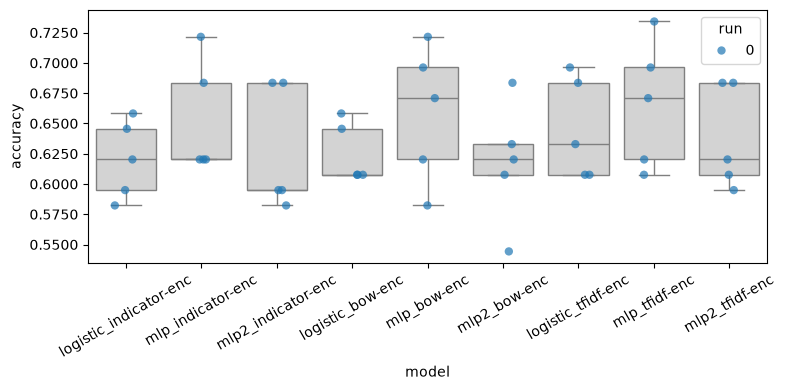

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.0771
P(Tie)    = 0.1239
P(B wins) = 0.7990
Effect Size = 1.35

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.3001
P(Tie)    = 0.2289
P(B wins) = 0.4709
Effect Size = 0.25

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.8926
P(Tie)    = 0.0937
P(B wins) = 0.0137
Effect Size = -2.43


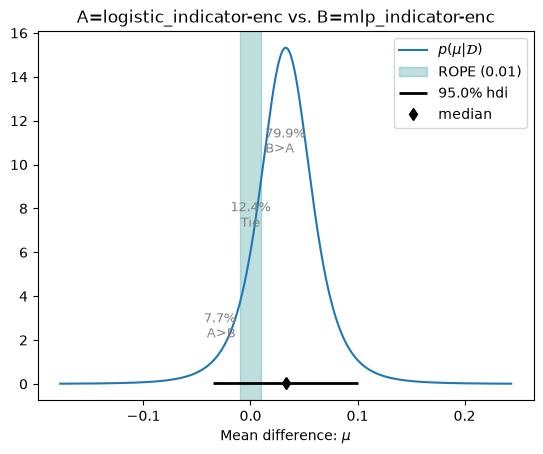

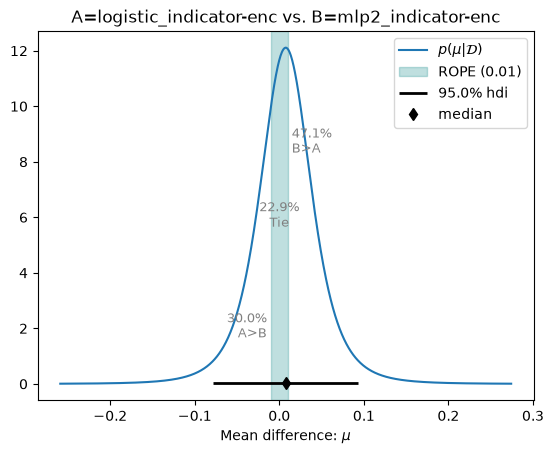

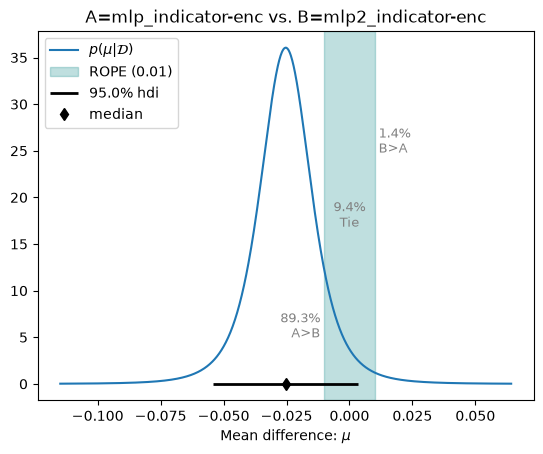

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.01

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

from pathlib import Path
import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [25]:

from scipy.sparse import csr_matrix

# Original MLP
def mlp_predict(texts):
    return smlp.predict_probs(
        texts,
        mlp_model,
        token_indicator_encoder
    )

# Modified MLP
def mlp2_predict(texts):
    return smlp2.predict_probs2(
        texts,
        mlp2_model,
        token_indicator_encoder
    )

# Log-linear model
def logistic_predict(texts):
    # Use Project1's probability function when available
    if hasattr(Project1.loglin, "predict_probs"):
        return Project1.loglin.predict_probs(
            texts,
            logistic_model,
            token_indicator_encoder
        )

    # Fallback for a fitted scikit-learn logistic model
    X = csr_matrix([
        token_indicator_encoder(text)
        for text in texts
    ])

    return logistic_model.predict_proba(X)

In [26]:
test_text = ["Climate change is a serious problem."]

print("Original MLP:", mlp_predict(test_text))
print("Modified MLP:", mlp2_predict(test_text))
print("Log-linear:", logistic_predict(test_text))

Original MLP: [[0.24514893 0.11647917 0.63837194]]
Modified MLP: [[0.20304032 0.06077518 0.73618454]]
Log-linear: [[0.09396002 0.05039353 0.85564645]]



Tweet 1: Can @user use $866,615 of jet fuel on His #EarthDay trip to Florida? YES HE CAN!!! -mao @user #FAIL
True class: none

--- Log-linear ---
Prediction: none
Probabilities: [9.823e-01 5.000e-04 1.720e-02]
Explanation: [(np.str_('user'), 0.1516739807608601), (np.str_('FAIL'), 0.08318673759423591), (np.str_('YES'), 0.07490827794269805), (np.str_('trip'), 0.06949630879526662), (np.str_('EarthDay'), -0.06128851310220712), (np.str_('His'), 0.055584444007891344), (np.str_('use'), -0.03981386521972685), (np.str_('CAN'), 0.035002228680564906), (np.str_('mao'), 0.03259614663640662), (np.str_('HE'), 0.03224445398118849)]


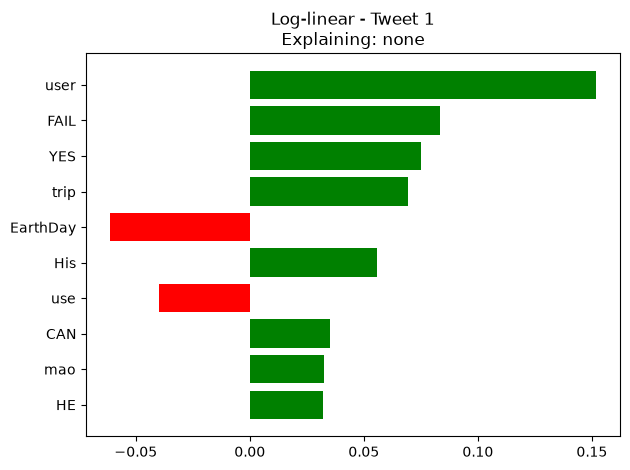


--- Original MLP ---
Prediction: none
Probabilities: [0.9289 0.0022 0.0688]
Explanation: [(np.str_('FAIL'), 0.06787751617553874), (np.str_('user'), 0.06425424480271369), (np.str_('YES'), 0.05034978809288792), (np.str_('trip'), 0.033852170575702376), (np.str_('His'), 0.028602408433827334), (np.str_('jet'), 0.023605020154770825), (np.str_('866'), 0.021139675263850334), (np.str_('CAN'), 0.019942605707842728), (np.str_('mao'), 0.017200562262964854), (np.str_('use'), -0.014610166784371235)]


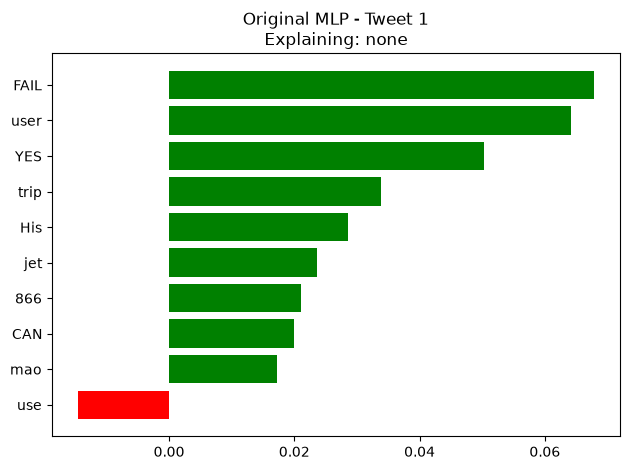


--- Modified MLP ---
Prediction: none
Probabilities: [9.622e-01 6.000e-04 3.710e-02]
Explanation: [(np.str_('FAIL'), 0.05072262736902631), (np.str_('user'), 0.04343052184078593), (np.str_('YES'), 0.04273498072299421), (np.str_('CAN'), 0.03419152250674354), (np.str_('trip'), 0.03329647737549431), (np.str_('mao'), 0.03103354283860407), (np.str_('Florida'), 0.023955841821672662), (np.str_('His'), 0.02075586151507287), (np.str_('866'), 0.02022377621742648), (np.str_('EarthDay'), 0.019864919236061325)]


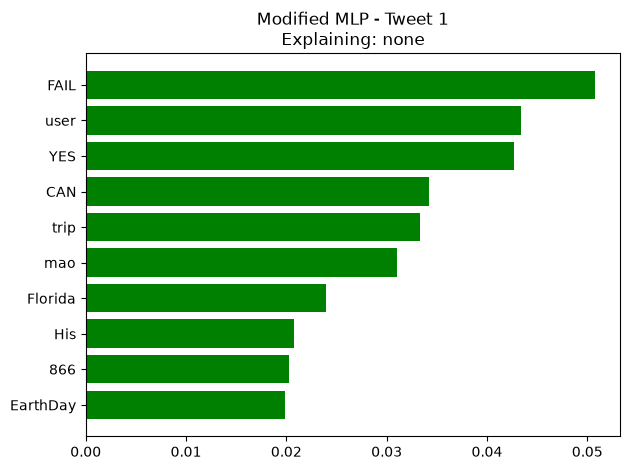


Tweet 2: .@whelan60 "While this debate goes on, yet more time is wasted." #thedrum
True class: none

--- Log-linear ---
Prediction: none
Probabilities: [0.9303 0.0167 0.053 ]
Explanation: [(np.str_('thedrum'), 0.21678553368222606), (np.str_('this'), 0.12503996712005272), (np.str_('more'), 0.07037318938739527), (np.str_('While'), -0.06532054309912327), (np.str_('is'), 0.041410036594814036), (np.str_('yet'), -0.033400912505347546), (np.str_('time'), -0.024208835124376535), (np.str_('on'), -0.015650082660662316), (np.str_('debate'), -0.011433060871991278), (np.str_('wasted'), -0.009924181588384913)]


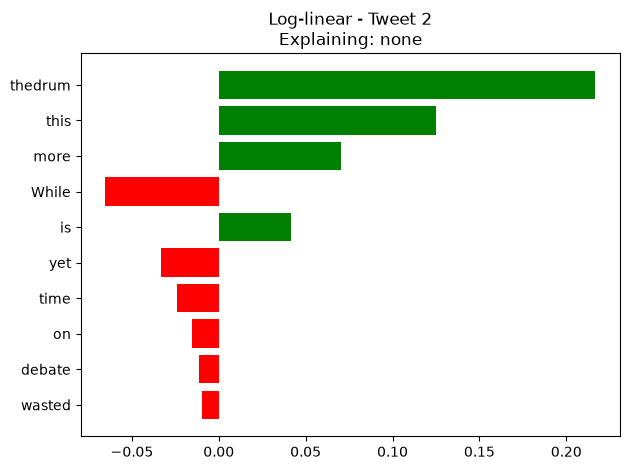


--- Original MLP ---
Prediction: none
Probabilities: [0.8085 0.024  0.1676]
Explanation: [(np.str_('thedrum'), 0.06420053717669184), (np.str_('this'), 0.057708357638684295), (np.str_('more'), 0.02600471311807685), (np.str_('yet'), 0.023411228703235153), (np.str_('on'), 0.01633429563616426), (np.str_('goes'), 0.013801843540721755), (np.str_('debate'), 0.013194779234460552), (np.str_('whelan60'), -0.01024691723369654), (np.str_('time'), 0.00450691496215115), (np.str_('While'), 0.0030888670722350004)]


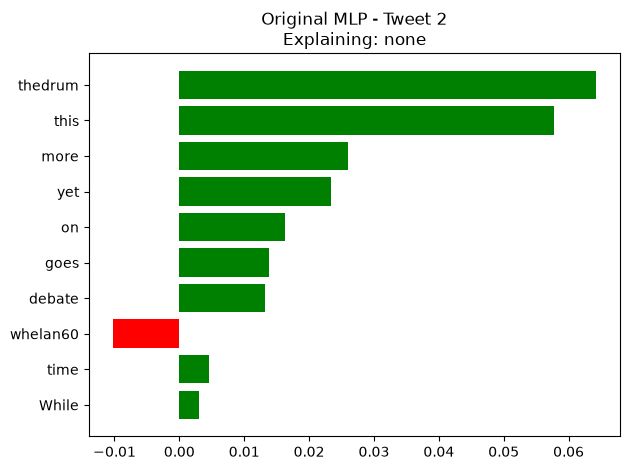


--- Modified MLP ---
Prediction: none
Probabilities: [0.7855 0.0133 0.2012]
Explanation: [(np.str_('thedrum'), 0.11226537284426669), (np.str_('this'), 0.06351333206523194), (np.str_('more'), 0.039259511183557326), (np.str_('on'), 0.03676203418685322), (np.str_('wasted'), -0.030263961017491025), (np.str_('yet'), 0.028251428204209814), (np.str_('whelan60'), 0.022993853439442175), (np.str_('goes'), -0.009903431244540479), (np.str_('is'), 0.009077285302619774), (np.str_('time'), -0.005015622948798617)]


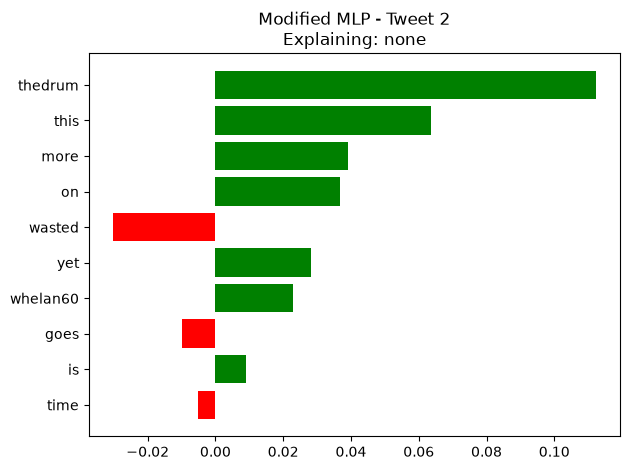


Tweet 3: Sir David Attenborough and @user  dissgussing the planet future. The room doesn't get any better than this.
True class: favor

--- Log-linear ---
Prediction: none
Probabilities: [0.6748 0.0042 0.321 ]
Explanation: [(np.str_('user'), -0.3040534501694827), (np.str_('future'), 0.15985871435284915), (np.str_('this'), -0.15493688583146725), (np.str_('dissgussing'), -0.1534331621433672), (np.str_('room'), 0.12470831611284933), (np.str_('and'), 0.11009520294953909), (np.str_('than'), -0.09303050053836649), (np.str_('doesn'), -0.07741664922938164), (np.str_('Sir'), 0.06261955554075752), (np.str_('planet'), 0.0580880574975548)]


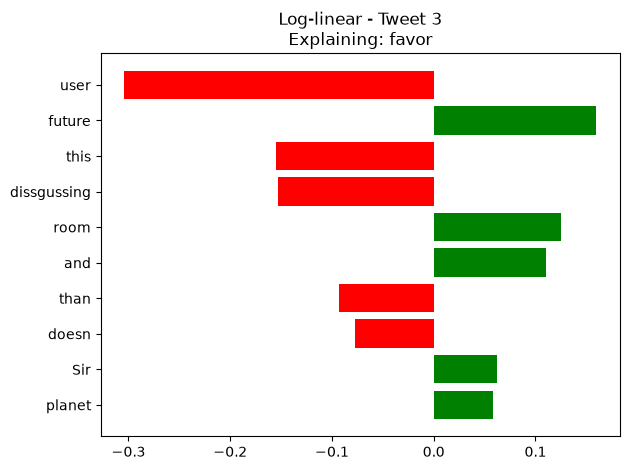


--- Original MLP ---
Prediction: none
Probabilities: [0.5216 0.0287 0.4497]
Explanation: [(np.str_('user'), -0.11342574782743761), (np.str_('future'), 0.09942973472685868), (np.str_('planet'), 0.07173728462390992), (np.str_('better'), -0.06709450558290239), (np.str_('doesn'), -0.052544220003442874), (np.str_('room'), 0.048715108333661904), (np.str_('t'), -0.04446312662636114), (np.str_('than'), -0.041586531285353744), (np.str_('Sir'), 0.038943369526679254), (np.str_('and'), 0.034910130467862295)]


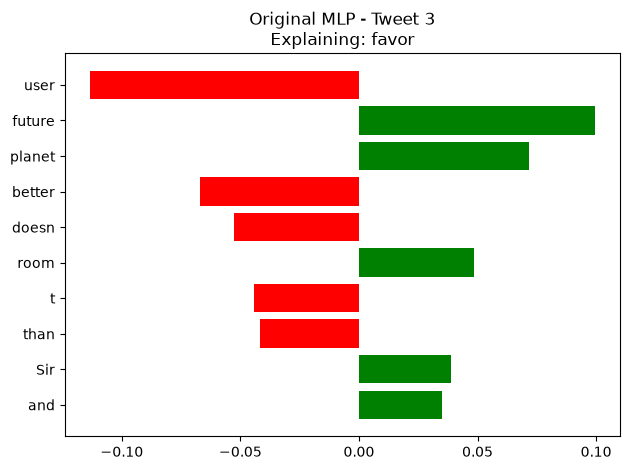


--- Modified MLP ---
Prediction: favor
Probabilities: [0.4528 0.0089 0.5383]
Explanation: [(np.str_('user'), -0.11677822250251708), (np.str_('future'), 0.10355257330674333), (np.str_('planet'), 0.06867709820967256), (np.str_('better'), -0.06680959322009114), (np.str_('Sir'), 0.065234626631255), (np.str_('than'), -0.043439125782646595), (np.str_('doesn'), -0.03795007111109726), (np.str_('this'), -0.037242077069184275), (np.str_('and'), 0.03410345151067566), (np.str_('t'), -0.03361723447590988)]


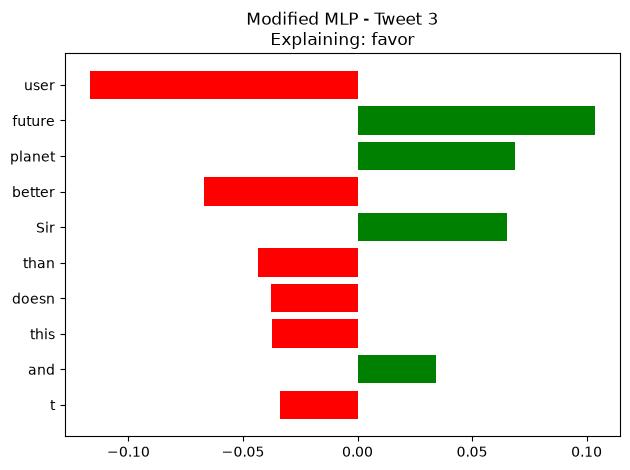

In [27]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

tweets = [1, 2, 3]

for tweet_id in tweets:

    example = dataset["validation"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text])[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [28]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.0981,0.0607,0.8412,1.3453
1,Log-linear,Modified MLP,0.3525,0.1161,0.5314,0.2453
2,MLP,Modified MLP,0.9388,0.0395,0.0217,-2.4343


In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.6203     0.5837  0.5053 0.5178
     mlp_indicator-enc    0.6532     0.6119  0.5245 0.5361
    mlp2_indicator-enc    0.6278     0.4560  0.4643 0.4527
      logistic_bow-enc    0.6253     0.5854  0.4914 0.5033
           mlp_bow-enc    0.6582     0.5504  0.4979 0.4987
          mlp2_bow-enc    0.6177     0.4486  0.4595 0.4504
    logistic_tfidf-enc    0.6456     0.5019  0.4667 0.4499
         mlp_tfidf-enc    0.6658     0.4876  0.4927 0.4839
        mlp2_tfidf-enc    0.6380     0.4690  0.4699 0.4595
